# Experiment 3: Selfish Voting Ring

Standalone reproduction of the selfish voting-ring experiment from `simulation.ipynb`. The selfish post has quality `0.1` and remains eligible for honest-player selection. Selfish players still deliberately vote for it. The no-sigmoid run uses the baseline reward formula; the sigmoid run applies content-quality attenuation and a behavioral gate to experimental rewards.


In [10]:
import math
from dataclasses import dataclass, field
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kendalltau, spearmanr

A = 0.02
B = 0.0001
REGEN = 3 / (5 * 24 * 60 * 60)
REWARD_POOL_SHARE = 0.75
REWARD_OFFSET = 0.0049
REWARD_DIVISOR = 50.0
ATTENTION_SPAN = 10
USE_QUALITY_CSV = False

plt.rcParams["figure.dpi"] = 110
plt.style.use("seaborn-v0_8-whitegrid")
print(f"a={A}, b={B}, regen={REGEN:.10f}, attention span={ATTENTION_SPAN}")
print(f"Use quality CSV: {USE_QUALITY_CSV}")

def make_vote_rounds(total_rounds: int, post_count: int) -> set[int]:
    """Return evenly spaced 1-based voting rounds, one per post when possible."""
    if total_rounds < 1 or post_count < 1:
        raise ValueError("total_rounds and post_count must be positive")
    if post_count == 1:
        return {1}
    if post_count >= total_rounds:
        return set(range(1, total_rounds + 1))
    return {
        1 + math.floor(index * (total_rounds - 1) / (post_count - 1))
        for index in range(post_count)
    }


a=0.02, b=0.0001, regen=0.0000069444, attention span=10
Use quality CSV: False


In [11]:
@dataclass
class SimulationResult:
    rounds: np.ndarray
    t_ideal_rank: np.ndarray
    kendall_tau: np.ndarray
    spearman_rho: np.ndarray
    final_order: np.ndarray
    ideal_order: np.ndarray
    ideal_scores: np.ndarray
    scores: np.ndarray
    reward_scores: np.ndarray
    vote_counts: np.ndarray
    selfish_post_id: int | None = None


class CurationSimulation:
    """Round-based curation model with explicit post ordering and player VP."""

    def __init__(
        self,
        players: int,
        posts: int,
        rounds: int,
        regen: float = REGEN,
        attention_span: int = ATTENTION_SPAN,
        seed: int = 42,
        selfish_players: int = 0,
        quality_probabilities: np.ndarray | None = None,
        selfish_quality_target: bool = False,
        score_sigmoid_slope: float | None = None,
        score_sigmoid_midpoint: float = 0.5,
        whale_voting_power: float = 1.0,
    ):
        if selfish_players < 0 or selfish_players > players:
            raise ValueError("selfish_players must be between 0 and players")
        if selfish_quality_target and quality_probabilities is None:
            raise ValueError("selfish_quality_target requires quality_probabilities")
        if posts < 1 or players < 1 or rounds < 1:
            raise ValueError("players, posts, and rounds must be positive")
        if score_sigmoid_slope is not None and score_sigmoid_slope <= 0.0:
            raise ValueError("score_sigmoid_slope must be positive")
        if not 0.0 <= score_sigmoid_midpoint <= 1.0:
            raise ValueError("score_sigmoid_midpoint must be between 0 and 1")
        if whale_voting_power < 1.0:
            raise ValueError("whale_voting_power must be at least 1.0")

        self.players = players
        self.honest_players = players - selfish_players
        self.selfish_quality_target = selfish_quality_target
        self.posts = posts + (1 if selfish_players and not selfish_quality_target else 0)
        self.rounds = rounds
        self.regen = regen
        self.attention_span = attention_span
        self.selfish_players = selfish_players
        self.score_sigmoid_slope = score_sigmoid_slope
        self.score_sigmoid_midpoint = score_sigmoid_midpoint
        self.rng = np.random.default_rng(seed)

        if quality_probabilities is None:
            self.selfish_post_id = posts if selfish_players else None
            self.likability = self.rng.uniform(0.0, 1.0, size=(players, self.posts))
        else:
            quality_probabilities = np.asarray(quality_probabilities, dtype=float)
            if quality_probabilities.shape != (posts,):
                raise ValueError(f"quality_probabilities must have shape ({posts},)")
            if np.any((quality_probabilities < 0.0) | (quality_probabilities > 1.0)):
                raise ValueError("quality_probabilities must be between 0 and 1")
            self.selfish_post_id = int(np.argmin(quality_probabilities)) if selfish_quality_target else (posts if selfish_players else None)
            self.likability = np.tile(quality_probabilities, (players, 1))
            if selfish_players and not selfish_quality_target:
                self.likability = np.column_stack((self.likability, np.zeros(players)))

        self.voting_power = np.ones(players, dtype=float)
        self.voting_power_cap = np.ones(players, dtype=float)
        if selfish_players:
            whale_id = players - 1
            self.voting_power[whale_id] = whale_voting_power
            self.voting_power_cap[whale_id] = whale_voting_power

        self.voted = np.zeros((players, self.posts), dtype=bool)
        self.scores = np.zeros(self.posts, dtype=float)
        self.reward_scores = np.zeros(self.posts, dtype=float)
        self.vote_counts = np.zeros(self.posts, dtype=int)
        if self.selfish_post_id is not None and not selfish_quality_target:
            # Keep the selfish post visible to honest voters with low quality.
            self.likability[:, self.selfish_post_id] = 0.1
        self.ideal_scores = self.likability.sum(axis=0)
        self.order = np.arange(self.posts)
        if selfish_quality_target:
            other_posts = self.order[self.order != self.selfish_post_id]
            self.order = np.concatenate((other_posts, np.array([self.selfish_post_id])))
        self.vote_rounds = self._make_vote_rounds()

    def _make_vote_rounds(self) -> set[int]:
        return make_vote_rounds(self.rounds, self.posts)

    def _score_factor(self, weight: float) -> float:
        if self.score_sigmoid_slope is None:
            return 1.0

        slope = self.score_sigmoid_slope
        midpoint = self.score_sigmoid_midpoint

        def sigmoid(value: float) -> float:
            return 1.0 / (1.0 + math.exp(-slope * value))

        lower = sigmoid(-slope * midpoint)
        upper = sigmoid(slope * (1.0 - midpoint))

        return (sigmoid(weight - midpoint) - lower) / (upper - lower)

    def _metrics(self) -> dict[str, float]:
        ideal_order = np.argsort(-self.ideal_scores, kind="stable")
        actual_order = self.order.copy()
        prefix = 0
        for actual_post, ideal_post in zip(actual_order, ideal_order):
            if actual_post != ideal_post:
                break
            prefix += 1

        ideal_position = np.empty(self.posts, dtype=int)
        ideal_position[ideal_order] = np.arange(self.posts)
        actual_positions = np.arange(self.posts)
        ideal_positions_in_actual_order = ideal_position[actual_order]
        tau = kendalltau(actual_positions, ideal_positions_in_actual_order).statistic
        rho = spearmanr(actual_positions, ideal_positions_in_actual_order).statistic
        return {
            "t_ideal_rank": float(prefix),
            "kendall_tau": float(np.nan_to_num(tau, nan=1.0)),
            "spearman_rho": float(np.nan_to_num(rho, nan=1.0)),
        }

    def _record(self, rows: list[dict[str, float]], round_number: int) -> None:
        row = self._metrics()
        row["round"] = float(round_number)
        rows.append(row)

    def run(self, tracking_interval: int = 1000) -> SimulationResult:
        tracked_rounds = set(range(0, self.rounds + 1, tracking_interval))
        tracked_rounds.update(self.vote_rounds)
        tracked_rounds.add(self.rounds)
        metrics: list[dict[str, float]] = []
        self._record(metrics, 0)

        for round_number in range(1, self.rounds + 1):
            self.voting_power = np.minimum(
                self.voting_power + self.regen,
                self.voting_power_cap,
            )

            if round_number in self.vote_rounds:
                for player_id in range(self.players):
                    if player_id >= self.honest_players and self.selfish_post_id is not None:
                        if self.voted[player_id, self.selfish_post_id]:
                            continue
                        selected_post = self.selfish_post_id
                        spend_weight = 1.0
                        score_weight = float(self.likability[player_id, selected_post])
                    else:
                        eligible = self.order[~self.voted[player_id, self.order]][:self.attention_span]
                        if len(eligible) == 0:
                            continue
                        selected_post = int(eligible[np.argmax(self.likability[player_id, eligible])])
                        score_weight = float(self.likability[player_id, selected_post])
                        spend_weight = score_weight

                    cost = A * self.voting_power[player_id] * spend_weight + B
                    spent = min(self.voting_power[player_id], cost)
                    score_contribution = spent * self._score_factor(score_weight)
                    baseline_reward = max(
                        0.0,
                        REWARD_POOL_SHARE
                        * (self.voting_power[player_id] * spend_weight - REWARD_OFFSET)
                        / REWARD_DIVISOR,
                    )
                    if self.score_sigmoid_slope is None:
                        reward_contribution = baseline_reward
                    else:
                        content_quality = self._score_factor(score_weight)
                        behavior_quality = 0.0 if player_id >= self.honest_players else 1.0
                        reward_contribution = (
                            baseline_reward * content_quality * behavior_quality
                        )
                    self.scores[selected_post] += score_contribution
                    self.reward_scores[selected_post] += reward_contribution
                    self.vote_counts[selected_post] += 1
                    self.voting_power[player_id] -= spent
                    self.voted[player_id, selected_post] = True

                self.order = np.argsort(-self.scores, kind="stable")

            if round_number in tracked_rounds:
                self._record(metrics, round_number)

        metric_frame = pd.DataFrame(metrics).drop_duplicates("round").sort_values("round")
        final_ideal_order = np.argsort(-self.ideal_scores, kind="stable")
        return SimulationResult(
            rounds=metric_frame["round"].to_numpy(),
            t_ideal_rank=metric_frame["t_ideal_rank"].to_numpy(),
            kendall_tau=metric_frame["kendall_tau"].to_numpy(),
            spearman_rho=metric_frame["spearman_rho"].to_numpy(),
            final_order=self.order.copy(),
            ideal_order=final_ideal_order,
            ideal_scores=self.ideal_scores.copy(),
            scores=self.scores.copy(),
            reward_scores=self.reward_scores.copy(),
            vote_counts=self.vote_counts.copy(),
            selfish_post_id=self.selfish_post_id,
        )

## Ring-size sweep and reward share

The selfish post has quality `0.1`, so honest players can select it when it appears in their attention window. Selfish players deliberately select it regardless of ranking. Baseline reward per vote is `0.75 * (voting_power * voting_weight - 0.0049) / 50`, clamped at zero.


,scenario,ring_size,selfish_post_final_position,positions_gained,final_t_ideal_rank,final_kendall_tau,final_spearman_rho,selfish_reward,honest_reward,total_reward,selfish_reward_share,honest_reward_share
0,Sigmoid-transformed score,1,101,0,1.0,0.820990,0.952207,0.002566,53.832312,53.834877,0.000048,0.999952
1,Sigmoid-transformed score,2,101,0,1.0,0.827723,0.960513,0.002566,53.526588,53.529154,0.000048,0.999952
2,Sigmoid-transformed score,3,101,0,0.0,0.778218,0.935958,0.002566,54.425993,54.428558,0.000047,0.999953
3,Sigmoid-transformed score,4,101,0,1.0,0.803168,0.944217,0.002566,53.775426,53.777992,0.000048,0.999952
4,Sigmoid-transformed score,5,101,0,1.0,0.805545,0.943366,0.002566,53.095727,53.098293,0.000048,0.999952


,scenario,ring_size,selfish_post_final_position,positions_gained,final_t_ideal_rank,final_kendall_tau,final_spearman_rho,selfish_reward,honest_reward,total_reward,selfish_reward_share,honest_reward_share
995,No sigmoid transformation,496,1,100,0.0,0.222574,0.315550,7.546194,74.057156,81.603350,0.092474,0.907526
996,No sigmoid transformation,497,1,100,0.0,0.318416,0.456284,7.561120,74.562696,82.123817,0.092070,0.907930
997,No sigmoid transformation,498,1,100,0.0,0.072475,0.114397,7.576047,74.468265,82.044312,0.092341,0.907659
998,No sigmoid transformation,499,1,100,0.0,0.257426,0.371532,7.590973,73.943354,81.534328,0.093102,0.906898
999,No sigmoid transformation,500,1,100,0.0,0.246733,0.354735,7.605900,74.471769,82.077669,0.092667,0.907333


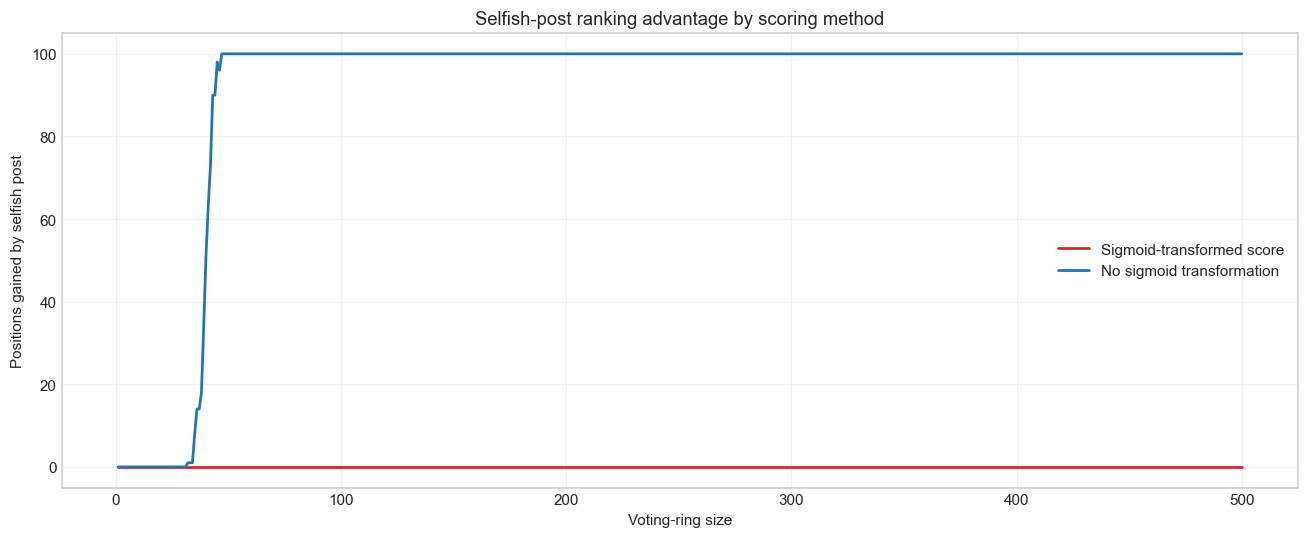

In [ ]:
def run_ring_sweep(score_sigmoid_slope: float | None, scenario: str) -> pd.DataFrame:
    ring_sizes = np.arange(1, 501)
    ring_results = []
    ring_ranking_results = []
    ring_regen = 3 / (5 * 24 * 60)

    for ring_size in ring_sizes:
        result = CurationSimulation(
            players=100 + int(ring_size),
            posts=100,
            rounds=200_000,
            regen=ring_regen,
            attention_span=10,
            seed=10_000 + int(ring_size),
            selfish_players=int(ring_size),
            score_sigmoid_slope=score_sigmoid_slope,
            score_sigmoid_midpoint=0.5,
        ).run(tracking_interval=500)

        selfish_position = int(np.flatnonzero(result.final_order == result.selfish_post_id)[0]) + 1
        initial_position = 101
        selfish_reward = float(result.reward_scores[result.selfish_post_id])
        total_reward = float(np.sum(result.reward_scores))
        honest_reward = total_reward - selfish_reward
        selfish_reward_share = selfish_reward / total_reward if total_reward else 0.0
        honest_reward_share = honest_reward / total_reward if total_reward else 0.0
        ring_results.append({
            "scenario": scenario,
            "ring_size": int(ring_size),
            "selfish_post_final_position": selfish_position,
            "positions_gained": initial_position - selfish_position,
            "final_t_ideal_rank": result.t_ideal_rank[-1],
            "final_kendall_tau": result.kendall_tau[-1],
            "final_spearman_rho": result.spearman_rho[-1],
            "selfish_reward": selfish_reward,
            "honest_reward": honest_reward,
            "total_reward": total_reward,
            "selfish_reward_share": selfish_reward_share,
            "honest_reward_share": honest_reward_share,
        })
        ring_ranking_results.append(result)

    return pd.DataFrame(ring_results), ring_ranking_results


ring_results, ring_ranking_results = run_ring_sweep(
    score_sigmoid_slope=10.0,
    scenario="Sigmoid-transformed score",
)
raw_ring_results, raw_ring_ranking_results = run_ring_sweep(
    score_sigmoid_slope=None,
    scenario="No sigmoid transformation",
)

ring_results = pd.concat([ring_results, raw_ring_results], ignore_index=True)
ring_ranking_results = ring_ranking_results + raw_ring_ranking_results
display(ring_results.head())
display(ring_results.tail())

fig, axis = plt.subplots(figsize=(12, 5))
for scenario, color in [
    ("Sigmoid-transformed score", "tab:red"),
    ("No sigmoid transformation", "tab:blue"),
]:
    scenario_results = ring_results[ring_results["scenario"] == scenario]
    axis.plot(
        scenario_results["ring_size"],
        scenario_results["positions_gained"],
        label=scenario,
        color=color,
        linewidth=1.8,
    )
axis.set_xlabel("Voting-ring size")
axis.set_ylabel("Positions gained by selfish post")
axis.set_title("Selfish-post ranking advantage by scoring method")
axis.grid(alpha=0.25)
axis.legend()
plt.tight_layout()
plt.show()


## Sigmoid-transformed reward share



,scenario,ring_size,selfish_reward,honest_reward,total_reward,selfish_reward_share,honest_reward_share,selfish_reward_share_percent,honest_reward_share_percent
0,Sigmoid-transformed score,1,0.002566,53.832312,53.834877,0.000048,0.999952,0.004766,99.995234
1,Sigmoid-transformed score,2,0.002566,53.526588,53.529154,0.000048,0.999952,0.004793,99.995207
2,Sigmoid-transformed score,3,0.002566,54.425993,54.428558,0.000047,0.999953,0.004714,99.995286
3,Sigmoid-transformed score,4,0.002566,53.775426,53.777992,0.000048,0.999952,0.004771,99.995229
4,Sigmoid-transformed score,5,0.002566,53.095727,53.098293,0.000048,0.999952,0.004832,99.995168


,scenario,ring_size,selfish_reward,honest_reward,total_reward,selfish_reward_share,honest_reward_share,selfish_reward_share_percent,honest_reward_share_percent
495,Sigmoid-transformed score,496,0.002566,53.431821,53.434386,0.000048,0.999952,0.004802,99.995198
496,Sigmoid-transformed score,497,0.002566,53.864412,53.866977,0.000048,0.999952,0.004763,99.995237
497,Sigmoid-transformed score,498,0.002566,53.822423,53.824989,0.000048,0.999952,0.004767,99.995233
498,Sigmoid-transformed score,499,0.002566,53.107731,53.110297,0.000048,0.999952,0.004831,99.995169
499,Sigmoid-transformed score,500,0.002566,53.826029,53.828595,0.000048,0.999952,0.004766,99.995234


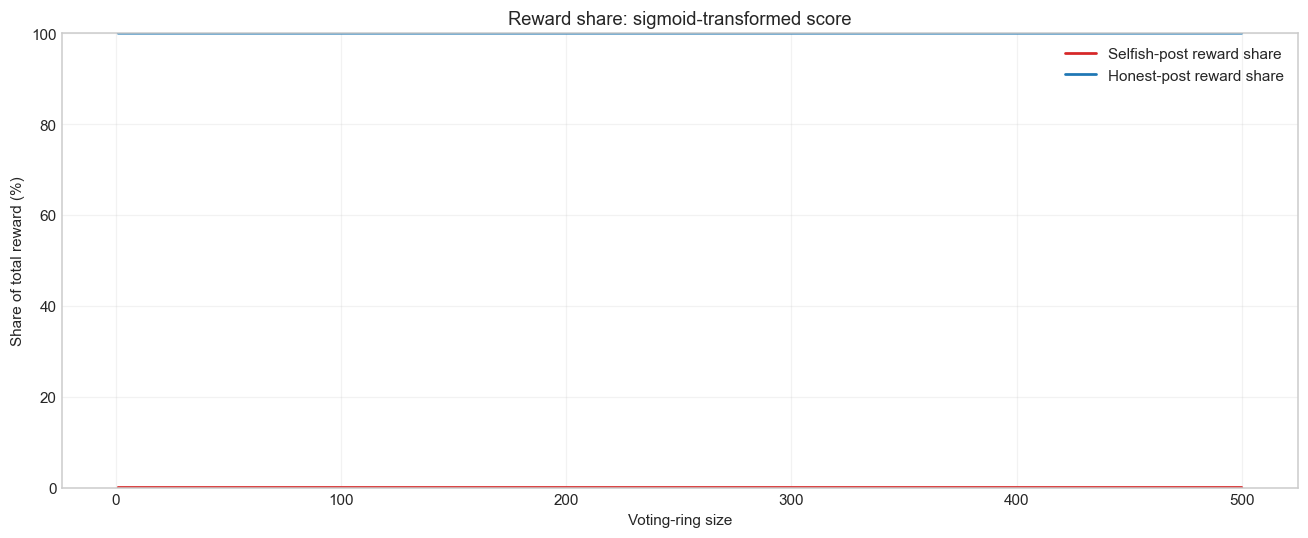

In [13]:
sigmoid_reward_share_results = ring_results[
    ring_results["scenario"] == "Sigmoid-transformed score"
][[
    "scenario",
    "ring_size",
    "selfish_reward",
    "honest_reward",
    "total_reward",
    "selfish_reward_share",
    "honest_reward_share",
]].copy()

sigmoid_reward_share_results["selfish_reward_share_percent"] = (
    sigmoid_reward_share_results["selfish_reward_share"] * 100.0
)
sigmoid_reward_share_results["honest_reward_share_percent"] = (
    sigmoid_reward_share_results["honest_reward_share"] * 100.0
)

display(sigmoid_reward_share_results.head())
display(sigmoid_reward_share_results.tail())

fig, axis = plt.subplots(figsize=(12, 5))
axis.plot(
    sigmoid_reward_share_results["ring_size"],
    sigmoid_reward_share_results["selfish_reward_share_percent"],
    label="Selfish-post reward share",
    color="tab:red",
    linewidth=1.8,
)
axis.plot(
    sigmoid_reward_share_results["ring_size"],
    sigmoid_reward_share_results["honest_reward_share_percent"],
    label="Honest-post reward share",
    color="tab:blue",
    linewidth=1.8,
)
axis.set_xlabel("Voting-ring size")
axis.set_ylabel("Share of total reward (%)")
axis.set_ylim(0, 100)
axis.set_title("Reward share: sigmoid-transformed score")
axis.grid(alpha=0.25)
axis.legend()
fig.tight_layout()
plt.show()


## No-sigmoid reward share



,scenario,ring_size,selfish_reward,honest_reward,total_reward,selfish_reward_share,honest_reward_share,selfish_reward_share_percent,honest_reward_share_percent
500,No sigmoid transformation,1,0.157576,74.564872,74.722449,0.002109,0.997891,0.210882,99.789118
501,No sigmoid transformation,2,0.172503,74.308995,74.481498,0.002316,0.997684,0.231605,99.768395
502,No sigmoid transformation,3,0.187429,75.067663,75.255093,0.002491,0.997509,0.249059,99.750941
503,No sigmoid transformation,4,0.202356,74.431804,74.634160,0.002711,0.997289,0.271131,99.728869
504,No sigmoid transformation,5,0.217282,73.782799,74.000081,0.002936,0.997064,0.293625,99.706375


,scenario,ring_size,selfish_reward,honest_reward,total_reward,selfish_reward_share,honest_reward_share,selfish_reward_share_percent,honest_reward_share_percent
995,No sigmoid transformation,496,7.546194,74.057156,81.603350,0.092474,0.907526,9.247407,90.752593
996,No sigmoid transformation,497,7.561120,74.562696,82.123817,0.092070,0.907930,9.206976,90.793024
997,No sigmoid transformation,498,7.576047,74.468265,82.044312,0.092341,0.907659,9.234092,90.765908
998,No sigmoid transformation,499,7.590973,73.943354,81.534328,0.093102,0.906898,9.310156,90.689844
999,No sigmoid transformation,500,7.605900,74.471769,82.077669,0.092667,0.907333,9.266711,90.733289


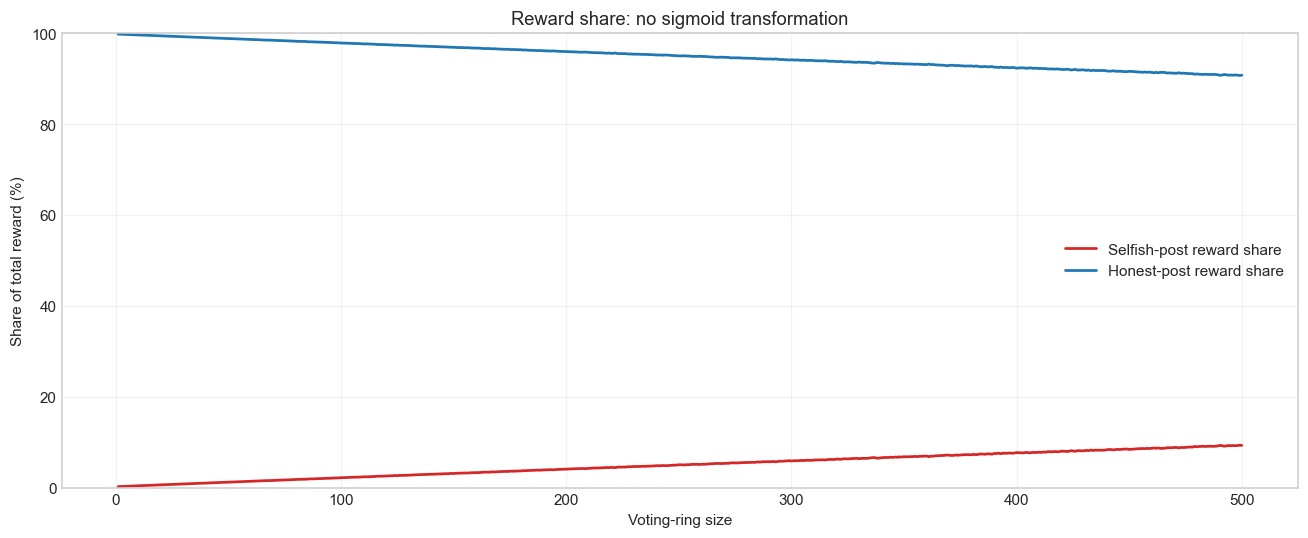

In [14]:
raw_reward_share_results = ring_results[
    ring_results["scenario"] == "No sigmoid transformation"
][[
    "scenario",
    "ring_size",
    "selfish_reward",
    "honest_reward",
    "total_reward",
    "selfish_reward_share",
    "honest_reward_share",
]].copy()

raw_reward_share_results["selfish_reward_share_percent"] = (
    raw_reward_share_results["selfish_reward_share"] * 100.0
)
raw_reward_share_results["honest_reward_share_percent"] = (
    raw_reward_share_results["honest_reward_share"] * 100.0
)

display(raw_reward_share_results.head())
display(raw_reward_share_results.tail())

fig, axis = plt.subplots(figsize=(12, 5))
axis.plot(
    raw_reward_share_results["ring_size"],
    raw_reward_share_results["selfish_reward_share_percent"],
    label="Selfish-post reward share",
    color="tab:red",
    linewidth=1.8,
)
axis.plot(
    raw_reward_share_results["ring_size"],
    raw_reward_share_results["honest_reward_share_percent"],
    label="Honest-post reward share",
    color="tab:blue",
    linewidth=1.8,
)
axis.set_xlabel("Voting-ring size")
axis.set_ylabel("Share of total reward (%)")
axis.set_ylim(0, 100)
axis.set_title("Reward share: no sigmoid transformation")
axis.grid(alpha=0.25)
axis.legend()
fig.tight_layout()
plt.show()
